In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('default')
data = pd.read_csv("data/viterbi_data.csv")
data

,data_type,first_subnormal,first_underflow,first_all_zero_row,subnormal_count,underflow_count,sequence_length,execution_time_ms,maximum_rss_kb
0,float,55,67,71,47,11,100000,104.19,10276
1,double,507,535,543,113,12,100000,95.67,13356
2,long_double,8194,8223,8229,121,13,100000,136.63,19620


In [2]:
data_types = data["data_type"].unique()
data_types

<StringArray>
['float', 'double', 'long_double']
Length: 3, dtype: str

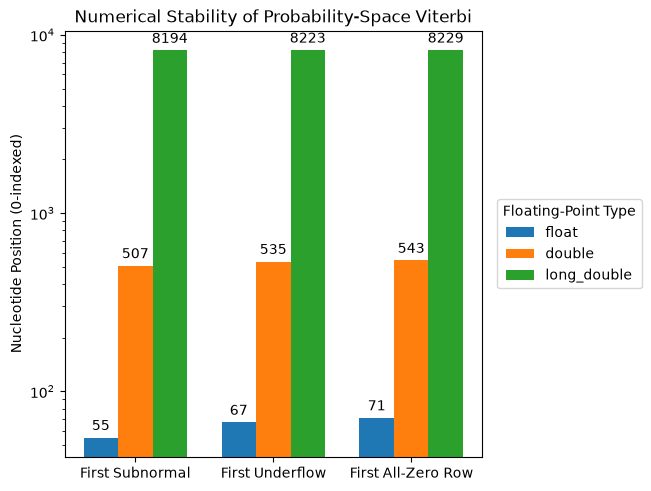

In [3]:
first_subnormals = data["first_subnormal"].unique()
first_underflow= data["first_underflow"].unique()
first_all_zeroes = data["first_all_zero_row"].unique()
stats = {
    'float': [first_subnormals[0], first_underflow[0], first_all_zeroes[0]],
    'double': [first_subnormals[1], first_underflow[1], first_all_zeroes[1]],
    'long_double': [first_subnormals[2], first_underflow[2], first_all_zeroes[2]]
}
fig, ax = plt.subplots(layout='constrained')

tick_labels = ['First Subnormal', 'First Underflow', 'First All-Zero Row']

res = ax.grouped_bar(stats, tick_labels=tick_labels, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

# Add some text for labels, title, etc.
ax.set_yscale('log')
ax.set_ylabel('Nucleotide Position (0-indexed)')
ax.set_title('Numerical Stability of Probability-Space Viterbi')
ax.legend(
    title='Floating-Point Type',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)
fig.savefig('figures/underflow_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

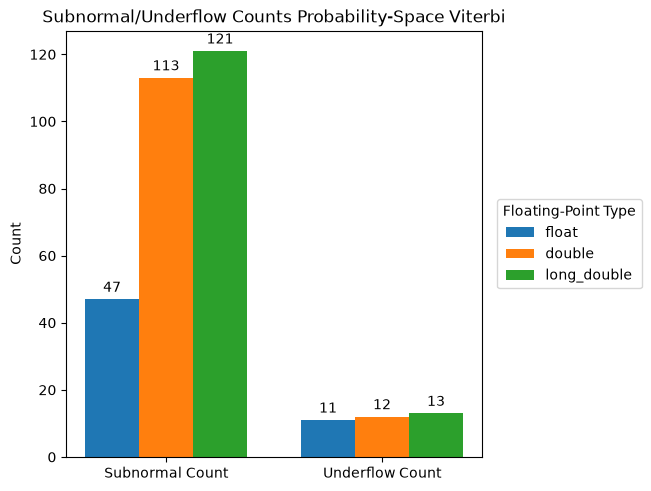

In [4]:
subnormal_count = data["subnormal_count"].unique()
underflow_count= data["underflow_count"].unique()
stats = {
    'float': [subnormal_count[0], underflow_count[0]],
    'double': [subnormal_count[1], underflow_count[1]],
    'long_double': [subnormal_count[2], underflow_count[2]]
}
fig, ax = plt.subplots(layout='constrained')

tick_labels = ['Subnormal Count', 'Underflow Count']

res = ax.grouped_bar(stats, tick_labels=tick_labels, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

# Add some text for labels, title, etc.
ax.set_ylabel('Count')
ax.set_title('Subnormal/Underflow Counts Probability-Space Viterbi')
ax.legend(
    title='Floating-Point Type',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)
fig.savefig('figures/underflow_count_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

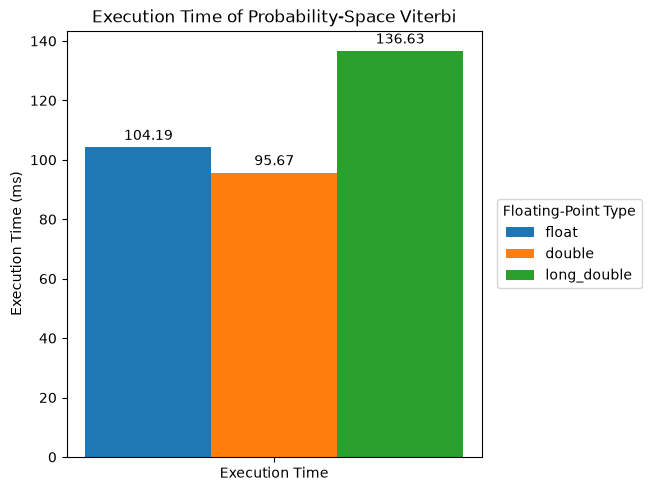

In [5]:
execution_time = data["execution_time_ms"].unique()
stats = {
    'float': [execution_time[0]],
    'double': [execution_time[1]],
    'long_double': [execution_time[2]]
}
fig, ax = plt.subplots(layout='constrained')

tick_labels = ['Execution Time']

res = ax.grouped_bar(stats, tick_labels=tick_labels, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

# Add some text for labels, title, etc.
ax.set_ylabel('Execution Time (ms)')
ax.set_title('Execution Time of Probability-Space Viterbi')
ax.legend(
    title='Floating-Point Type',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)
fig.savefig('figures/duration_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

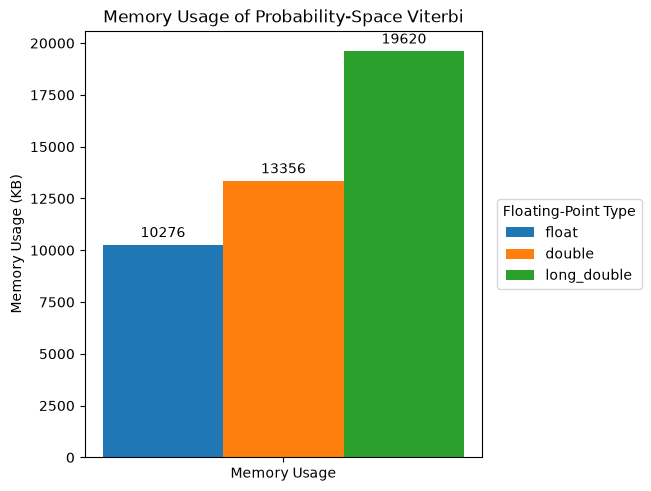

In [6]:
memory_usage = data["maximum_rss_kb"].unique()
stats = {
    'float': [memory_usage[0]],
    'double': [memory_usage[1]],
    'long_double': [memory_usage[2]]
}
fig, ax = plt.subplots(layout='constrained')

tick_labels = ['Memory Usage']

res = ax.grouped_bar(stats, tick_labels=tick_labels, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

# Add some text for labels, title, etc.
ax.set_ylabel('Memory Usage (KB)')
ax.set_title('Memory Usage of Probability-Space Viterbi')
ax.legend(
    title='Floating-Point Type',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)
fig.savefig('figures/mem_usage_statistics.png', dpi=300, bbox_inches='tight')
plt.show()